# Parte B — PD: regresión logística frente a un MLP

Capa delgada sobre `src/` (núcleo §5.8): el notebook no calcula nada por su cuenta, solo llama funciones del
repositorio y muestra lo que devuelven. **Se edita este `.py`; el `.ipynb` lo genera `python run.py notebooks`.**

- **Sección 1 (demo en vivo):** entrena la logística y el MLP con `configs/pd/demo.yaml` en una **carpeta temporal**.
  Es lo único que cambia con `SET`.
- **Secciones 2–4 (repaso de la Parte B):** solo leen lo versionado: `data/processed/resumen_datos.json`,
  `results/data/eda/post_preprocesamiento.json`, `configs/features.yaml`, `results/data/pd/` y las figuras de
  `blog/docs/figures/`.
- **Sección 5 (de la PD a la decisión):** solo lee `results/data/pd_umbral/` (`umbral.json`) y dos figuras del blog.

El notebook **nunca escribe** en `data/processed/`, `models/`, `results/` (incluida `results/data/pd_umbral/`),
`configs/pd/mlp_final.yaml` ni `blog/`.

**Cómo usar los moldes:** copia al `SET` de la sección 1.0 las claves que quieras cambiar (con su nuevo valor) y corre
todo (*Run All*). Una clave mal escrita es un error, igual que en `--set`.

## Moldes de los parámetros de la demo

Todas las claves de `configs/pd/demo.yaml` que se pueden cambiar en vivo, con su valor actual. `salida`, `modelos` y
`busqueda` no van: el notebook manda la salida y los modelos a la carpeta temporal, y la demo no viene de la
búsqueda.

### Claves comunes

```python
{
    "base_seed": 0,  # semilla del muestreo de datos.muestra y base de las semillas del MLP (base_seed + k)
    "datos.muestra": 50000,  # filas repartidas entre train, val y test en proporción a su tamaño; None = todas
    "semillas.n": 3,  # número de semillas del MLP (base_seed + 0, …, n − 1)
}
```

### Logística

```python
{
    "logistica.rejilla_C": [0.001, 0.0031623, 0.01],  # valores de C que se prueban (gana el de menor log-loss de val)
    "logistica.max_iter": 1000,  # iteraciones máximas de lbfgs
    "logistica.tol": 1e-06,  # tolerancia de lbfgs
}
```

### MLP

```python
{
    "mlp.capas": [32, 16, 32],  # neuronas de cada capa oculta (una entrada por capa)
    "mlp.activacion": "relu",  # activación de las capas ocultas: "relu", "leaky_relu" o "tanh"
    "mlp.dropout": 0.09416553239584849,  # probabilidad de dropout
    "mlp.l2": 4.451065531349953e-05,  # λ de la penalización (λ/2)‖W‖² (weight_decay; sin sesgos)
    "mlp.optimizador": "adam",  # optimizador: "adam" o "sgd"
    "mlp.lr": 0.004965184800549709,  # tasa de aprendizaje
    "mlp.momento": 0.9,  # momento de sgd (adam no lo usa)
    "mlp.batch": 512,  # tamaño del minilote
    "mlp.max_epocas": 20,  # máximo de épocas
    "mlp.paciencia": 5,  # épocas sin mejorar la pérdida de val antes de parar
    "mlp.device": "cpu",  # dispositivo de entrenamiento
    "mlp.pos_weight": 1.0,  # peso de la clase positiva en la BCE (debe ser 1, B-pd §3.2)
}
```

### Comando de terminal equivalente

La primera línea es la demo; la segunda, un ejemplo de modificación. Con otra muestra hay que cambiar también
`salida` (si no, el pre-chequeo falla porque `pred_test.parquet` tiene otros ids, B-pd §3.5) y, para no pisar los
modelos de la demo, `modelos`; `results/data/*_demo/` y `models/*_demo*` están ignoradas por git.

```bash
python run.py pd --config configs/pd/demo.yaml
python run.py pd --config configs/pd/demo.yaml --set datos.muestra=20000 --set 'mlp.capas=[64, 32]' --set salida=results/data/pd2_demo --set modelos=models/pd2_demo
```

## 1. Demo en vivo

El mismo código que la corrida reportada, con menos presupuesto (muestra, semillas, rejilla y épocas reducidas):
sirve para ver el flujo completo en menos de dos minutos, **no** para reportar cifras (esas están en la sección 4).
Desarrollo completo en el [blog 06](../blog/secciones/06-resultados-pd.md).

### 1.0 Parámetros

`CONFIG` y `SET` (mismas claves que `--set`; copia las de los moldes de arriba).

In [1]:
CONFIG = "configs/pd/demo.yaml"  # config de la demo (B6)
SET = {}  # cambios en vivo: {"clave.con.punto": valor}

### 1.1 Configuración resuelta

Se carga con el mismo cargador del CLI (una clave inexistente es un error) y se imprime: es la que se usa para
predecir qué cambiará antes de correr.

In [2]:
import tempfile  # carpeta temporal de la demo
import time  # duración de la demo
from pathlib import Path  # rutas

import pandas as pd  # tablas
from IPython.display import Image, display  # figuras PNG

from src.common.config import load_config  # cargador de YAML (features.yaml)
from src.common.notebooks import config_notebook  # config del notebook = config del CLI
from src.common.results import load_json  # lectura de los JSON versionados
from src.pd import tablas  # tablas y textos de este notebook (B9)
from src.pd import tablas_umbral  # tablas de la sección 5 (B11)
from src.pd.experimento import correr_pd  # run.py pd: logística + MLP (B5)
from src.viz.figs_pd import ENTRADA, generar, insumos_de_corrida  # figuras de la PD (B7)
from src.viz.figs_pd import SALIDA as FIGURAS_BLOG  # blog/docs/figures (solo lectura)

RESUMEN_DATOS = "data/processed/resumen_datos.json"  # resumen de la Parte A
POST_PREPROCESAMIENTO = "results/data/eda/post_preprocesamiento.json"  # descriptivo después del preprocesamiento
FEATURES = "configs/features.yaml"  # las 15 variables de originación
UMBRAL = "results/data/pd_umbral/umbral.json"  # resultados de B11 (sección 5)
FIGURAS_DEMO = ("pd-roc.png", "pd-ks.png", "pd-calibracion.png", "pd-aprendizaje.png", "pd-semillas.png",
                "pd-busqueda-logistica.png")  # la demo no tiene hpo_ensayos.json: no hay pd-busqueda-mlp
pd.set_option("display.width", 160)  # tablas anchas
pd.set_option("display.max_colwidth", 200)  # citas del diccionario completas

cfg = config_notebook(CONFIG, SET)  # config resuelta e impresa

Configuración final resuelta:
base_seed: 0
datos:
  muestra: 50000
logistica:
  rejilla_C:
  - 0.001
  - 0.0031623
  - 0.01
  max_iter: 1000
  tol: 1.0e-06
mlp:
  capas:
  - 32
  - 16
  - 32
  activacion: relu
  dropout: 0.09416553239584849
  l2: 4.451065531349953e-05
  optimizador: adam
  lr: 0.004965184800549709
  momento: 0.9
  batch: 512
  max_epocas: 20
  paciencia: 5
  device: cpu
  pos_weight: 1.0
busqueda:
  tipo: sin_busqueda
semillas:
  n: 3
salida: results/data/pd_demo
modelos: models/pd_demo


### 1.2 Entrenamiento en una carpeta temporal

`correr_pd` hace el pre-chequeo, la búsqueda de C de la logística y las semillas del MLP. La salida y los modelos
van **siempre** a la carpeta temporal, aunque `SET` cambie `salida` o `modelos`. Debajo: tiempo, filas por
partición, el MLP de esta corrida y la tabla logística frente a MLP (val y test; media y desviación entre semillas).

In [3]:
carpeta = Path(tempfile.mkdtemp(prefix="demo_pd_"))  # carpeta temporal (no se imprime)
inicio = time.perf_counter()  # reloj
demo = correr_pd(tablas.redirigir_salidas(cfg, carpeta))  # logística y MLP, salidas en la carpeta temporal
segundos = time.perf_counter() - inicio  # duración
insumos_demo = insumos_de_corrida(carpeta / tablas.SUBCARPETA_RESULTADOS)  # JSON y predicciones de esta corrida
print(f"Tiempo de la demo: {segundos:.1f} s")  # tiempo
print("Filas por partición:", tablas.filas_por_particion(insumos_demo["semillas"]))  # train, val, test
print(tablas.describir_mlp(demo["mlp"]))  # arquitectura, parámetros y semilla mediana
tablas.tabla_metricas(demo).T  # una columna por modelo

Muestra: datos.muestra=50000 → train 19005 · val 15397 · test 15598


Aviso: la config del MLP no es la de la búsqueda (difieren: max_epocas, paciencia, busqueda); n_configuraciones_busqueda, tiempo_busqueda_s y busqueda quedan en null
Semillas anteriores del MLP borradas: 0


Tiempo de la demo: 7.6 s
Filas por partición: {'train': 19005, 'val': 15397, 'test': 15598}
MLP: capas [32, 16, 32] · activación relu · 2673 parámetros · semilla mediana 1 de 3 · config de la búsqueda: no


,logistica,mlp
AUC val,0.664869,0.66357
AUC val (desv),0.0,0.005246
Gini val,0.329738,0.32714
Gini val (desv),0.0,0.010491
KS val,0.239976,0.236699
KS val (desv),0.0,0.009035
Brier val,0.170163,0.168737
Brier val (desv),0.0,0.000552
log-loss val,0.520131,0.515292
log-loss val (desv),0.0,0.001824


### 1.3 Figuras de esta corrida

Las mismas funciones que dibujan las figuras del blog, alimentadas con esta corrida y escritas en la carpeta
temporal: ROC, KS, calibración, aprendizaje de la semilla mediana, semillas y búsqueda de C.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


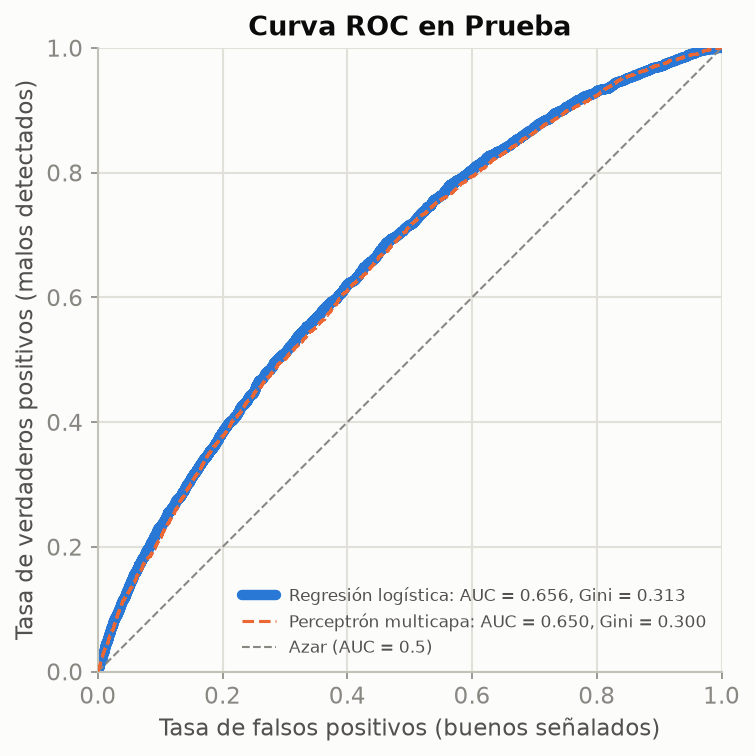

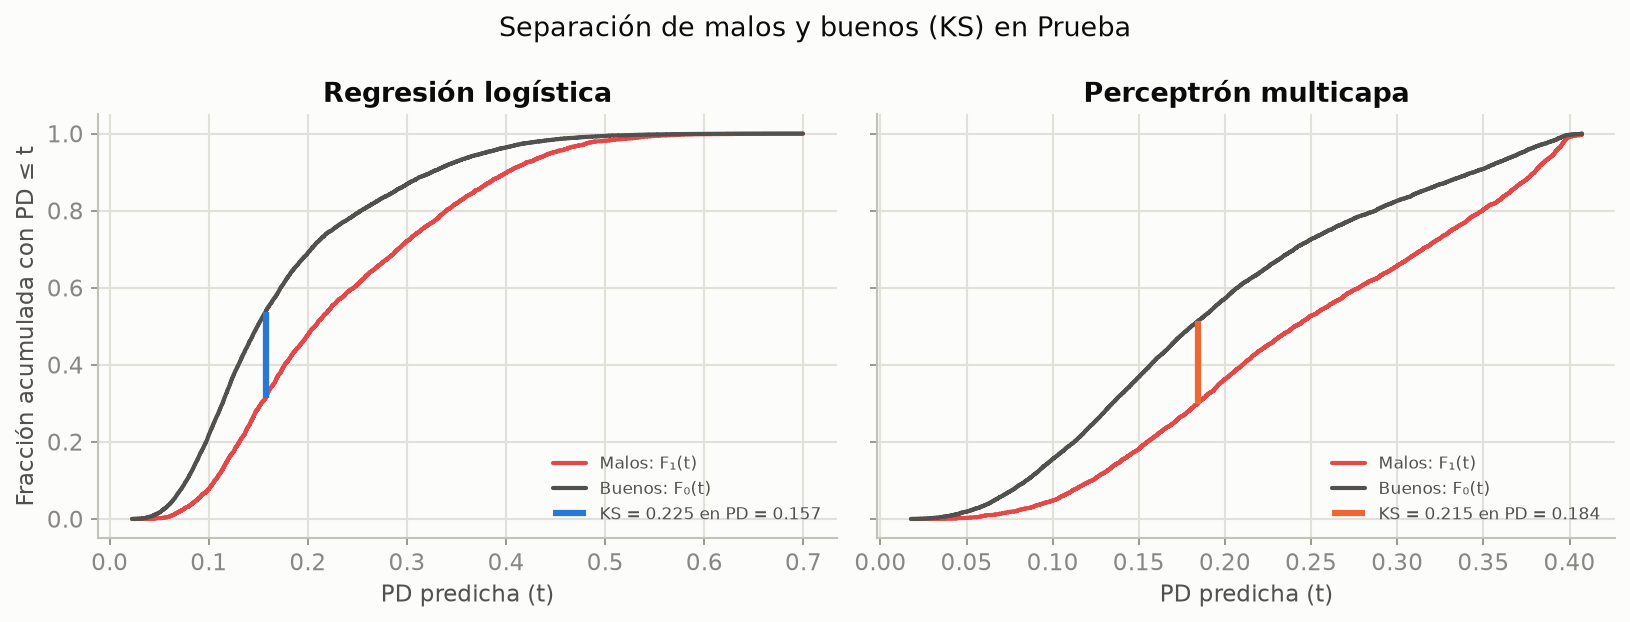

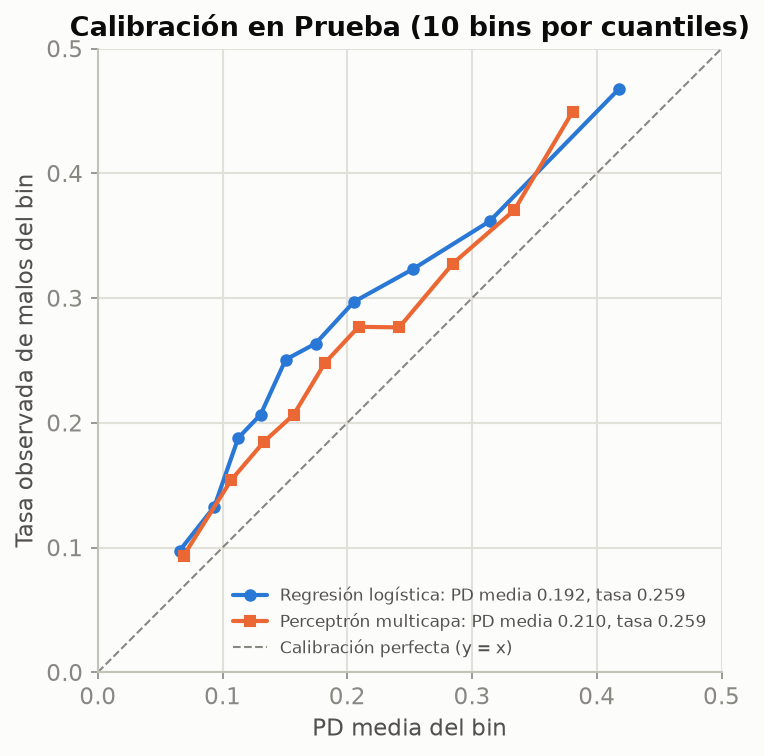

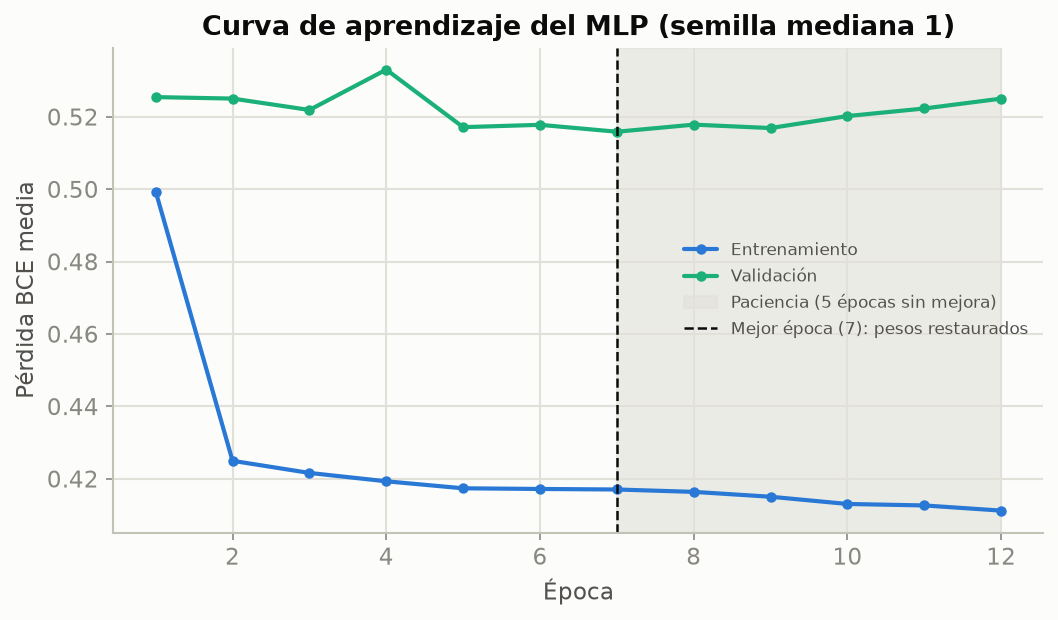

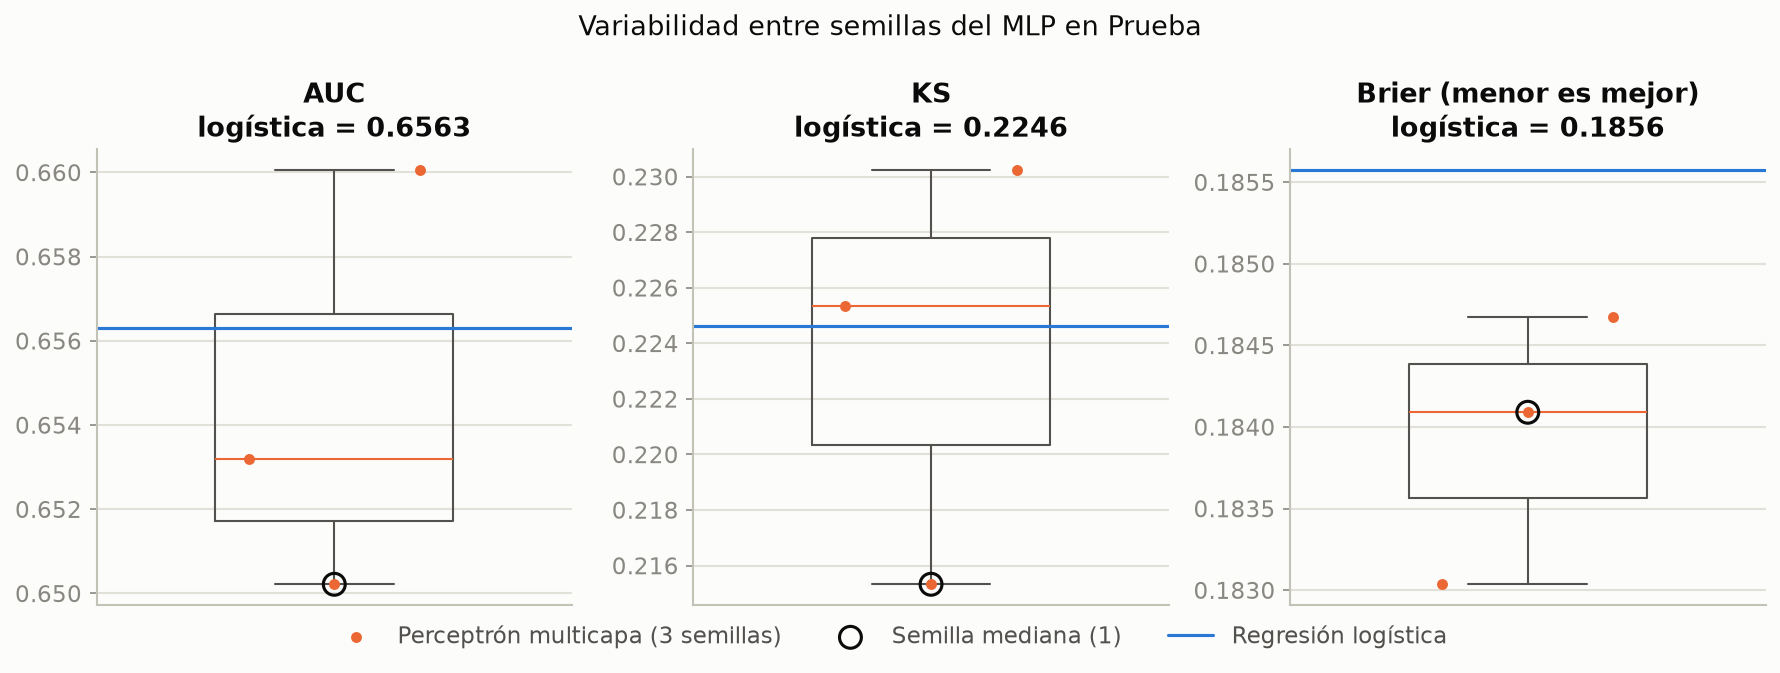

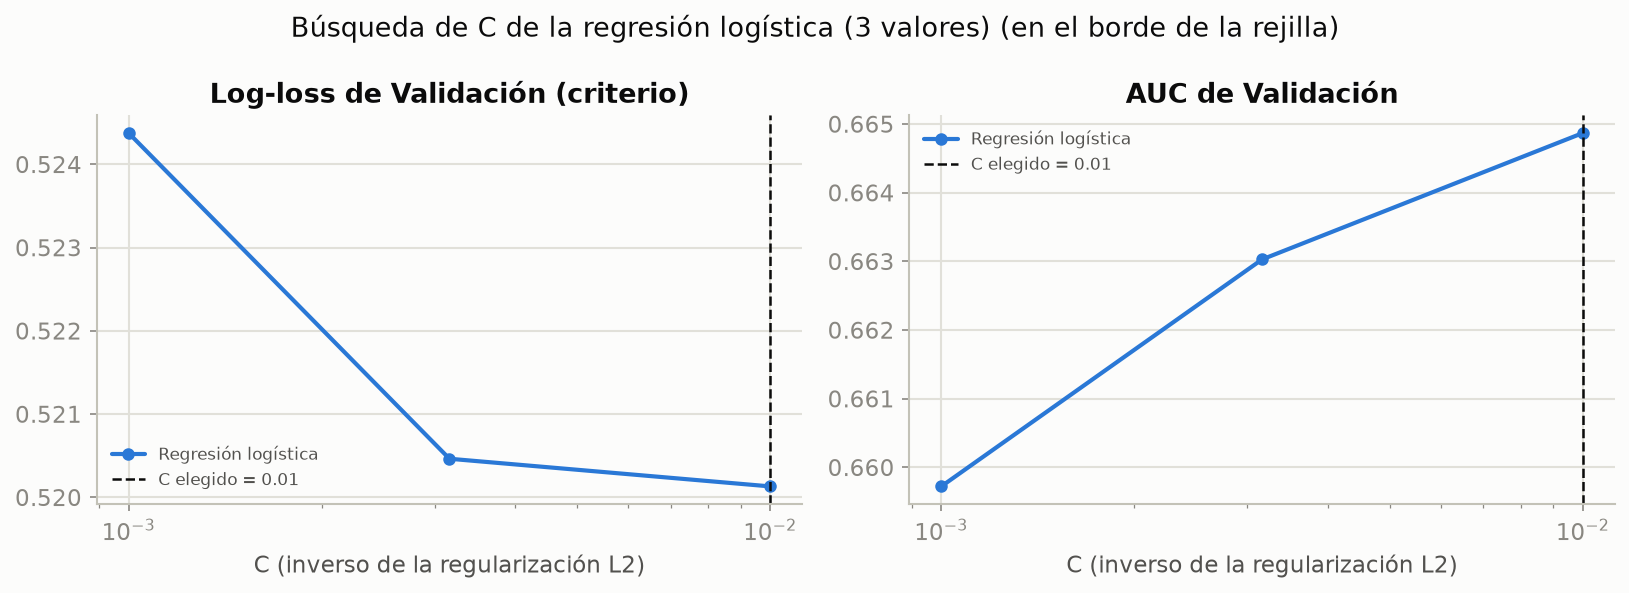

In [4]:
figuras_demo = {r.name: r for r in generar(destino=carpeta / "figuras", datos=insumos_demo)}  # nombre → ruta
for nombre in FIGURAS_DEMO:  # en orden
    display(Image(filename=str(figuras_demo[nombre])))  # figura

## 2. Datos que consume la PD (Parte A, solo lectura)

La PD se entrena con los datos que entrega la Parte A, sin cambiarlos. El análisis completo está en el notebook
`01_datos` y en el [blog 02](../blog/secciones/02-datos.md) y el [blog 03](../blog/secciones/03-descriptivo.md).

### 2.1 Partición temporal y tasa de malos

La partición es por fecha de originación (train, val y test en ese orden), para medir como se usaría el modelo:
con créditos posteriores a los de entrenamiento. Tasa de malos por partición y por año; los años posteriores a test
quedan fuera. La tasa de malos sube de train a test: esa deriva reaparece en la sección 5.5, cuando un corte de PD
elegido en val se aplica tal cual en test.

In [5]:
resumen_datos = load_json(RESUMEN_DATOS)  # resumen de la Parte A
display(tablas.tabla_particion(resumen_datos))  # cortes, n y tasa por partición
tablas.tabla_por_anio(resumen_datos)  # por año de originación

,hasta,n,tasa de malos
train,2012-12-31,90347,0.163027
val,2013-12-31,73194,0.229500
test,2014-12-31,74154,0.262171


,partición,créditos,fracción sin resolver (NA),tasa de malos (resueltos)
año,,,,
2007,train,603,0.000000,0.262023
2008,train,2393,0.000000,0.207271
2009,train,5281,0.000000,0.136906
2010,train,12537,0.000718,0.140405
2011,train,21721,0.091708,0.165188
2012,train,53367,0.066595,0.167306
2013,val,134755,0.456836,0.229500
2014,test,235628,0.685292,0.262171
2015,fuera,421094,0.926774,0.254613


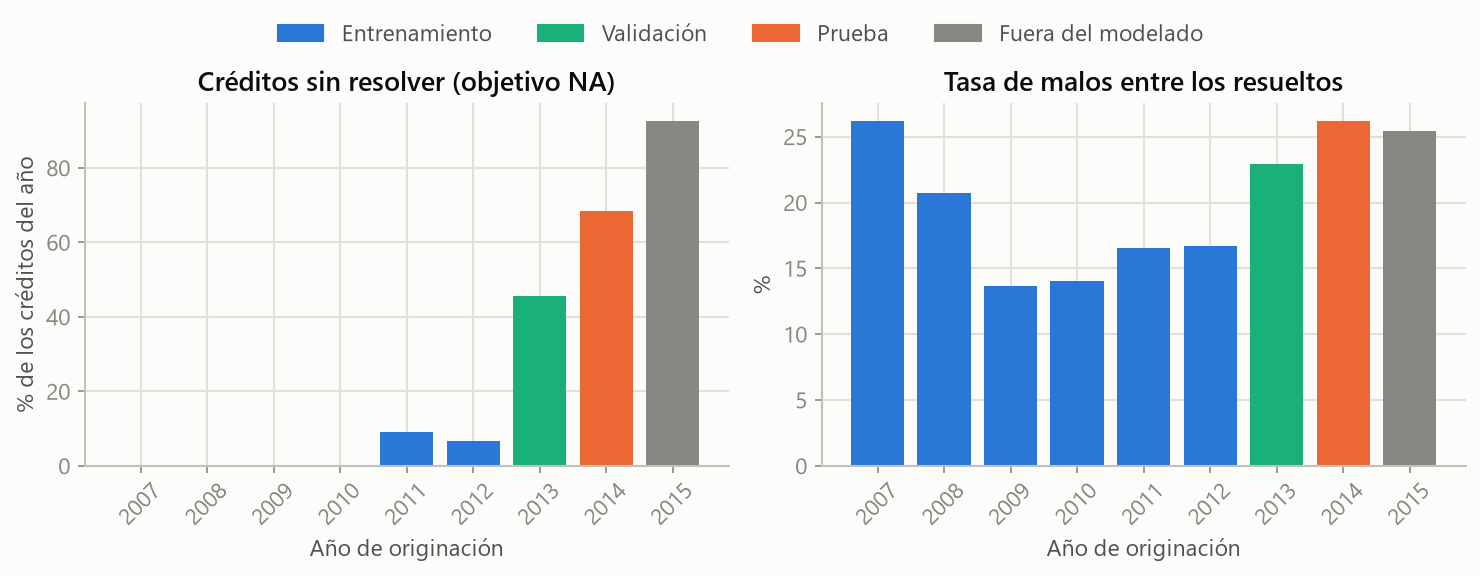

In [6]:
display(Image(filename=str(FIGURAS_BLOG / "datos-anio.png")))  # figura de la Parte A

### 2.2 Las variables de originación

Solo entran variables conocidas antes del desembolso (núcleo §5.7); el significado es la cita literal del
diccionario de Kaggle. El preprocesador de A se ajustó solo con train y B lo carga sin reajustar. La figura muestra
la tasa de malos por grupo de cada variable (línea discontinua = tasa de train).

In [7]:
tablas.tabla_variables(load_config(FEATURES))  # tipo, etiqueta, transformación y cita

,tipo,etiqueta,transformación,cita del diccionario
loan_amnt,num,Monto solicitado (USD),log1p,"The listed amount of the loan applied for by the borrower. If at some point in time, the credit department reduces the loan amount, then it will be reflected in this value."
term,cat,Plazo,ninguna,The number of payments on the loan. Values are in months and can be either 36 or 60.
emp_length,cat,Antigüedad en el empleo,ninguna,Employment length in years. Possible values are between 0 and 10 where 0 means less than one year and 10 means ten or more years.
home_ownership,cat,Vivienda,ninguna,"The home ownership status provided by the borrower during registration. Our values are: RENT, OWN, MORTGAGE, OTHER."
annual_inc,num,Ingreso anual (USD),log1p,The self-reported annual income provided by the borrower during registration.
purpose,cat,Destino del préstamo,ninguna,A category provided by the borrower for the loan request.
dti,num,Deuda mensual sobre ingreso mensual (%),ninguna,"A ratio calculated using the borrower’s total monthly debt payments on the total debt obligations, excluding mortgage and the requested LC loan, divided by the borrower’s self-reported monthly inc..."
delinq_2yrs,num,Moras de 30+ días en los últimos 2 años,ninguna,The number of 30+ days past-due incidences of delinquency in the borrower's credit file for the past 2 years
antiguedad_credito_anios,num,Años de historial crediticio,ninguna,earliest_cr_line: The month the borrower's earliest reported credit line was opened; issue_d: The month which the loan was funded
inq_last_6mths,num,Consultas de crédito en los últimos 6 meses,ninguna,The number of inquiries in past 6 months (excluding auto and mortgage inquiries)


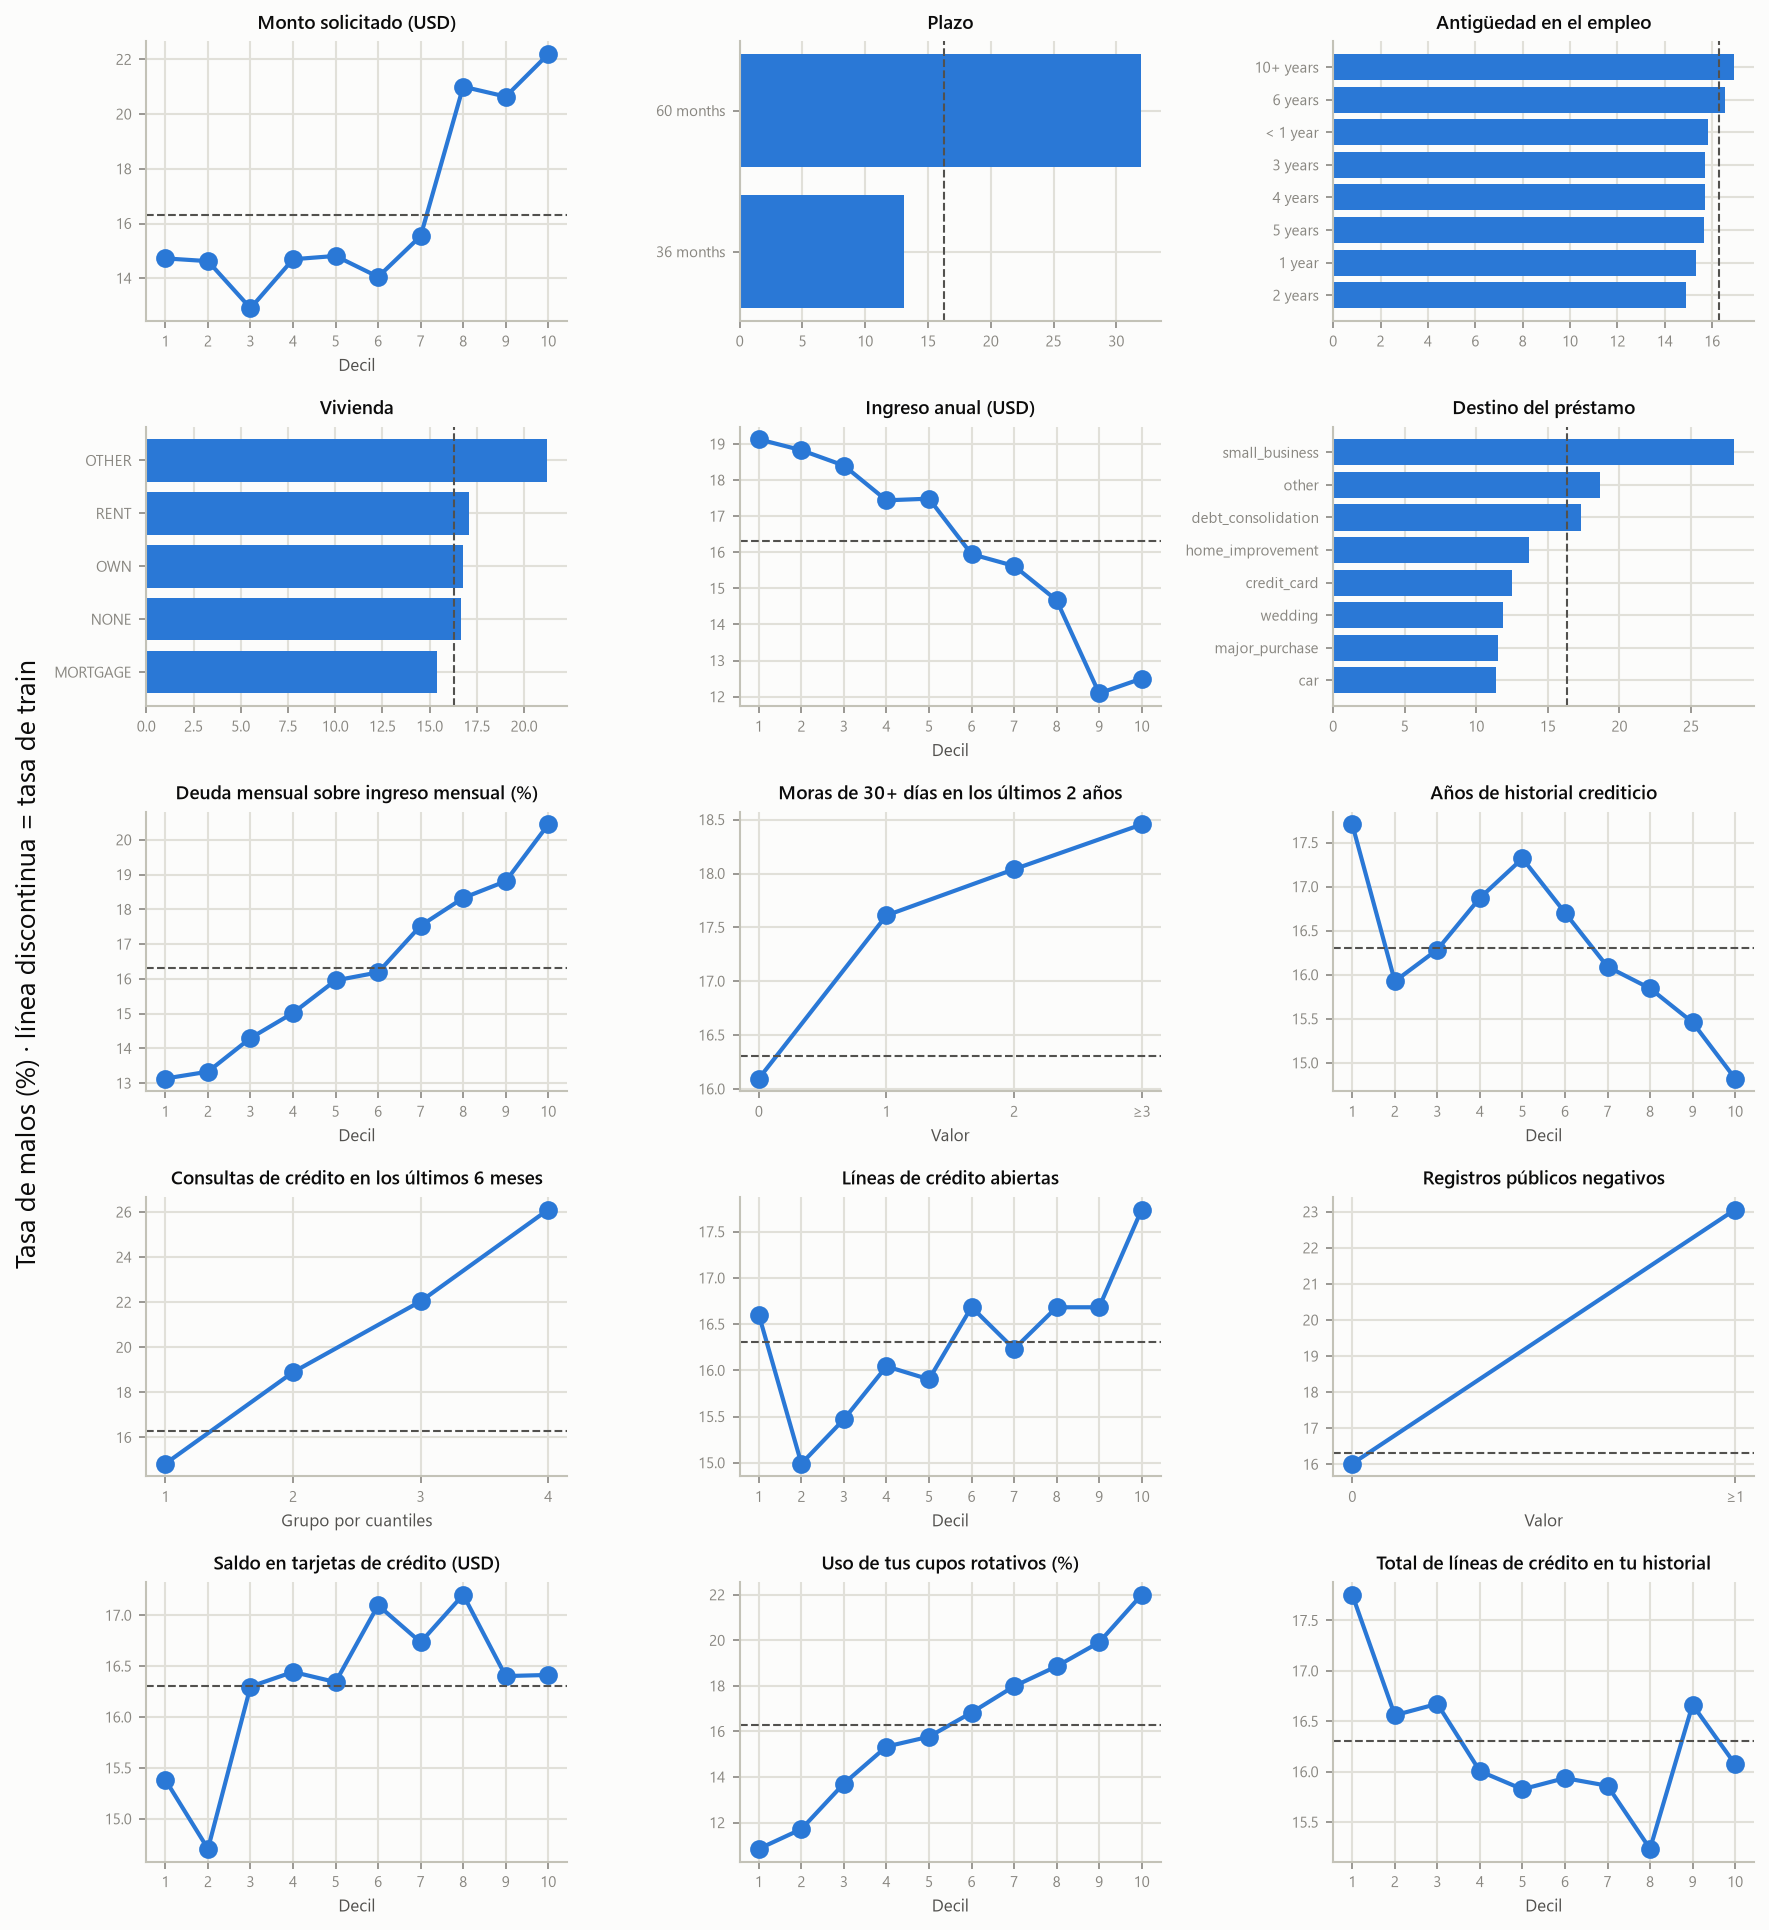

In [8]:
display(Image(filename=str(FIGURAS_BLOG / "eda-tasa-variables.png")))  # figura de la Parte A

### 2.3 Estabilidad entre particiones (PSI frente a train)

El PSI compara la distribución de cada variable en val y en test con la de train (después del preprocesamiento):
más alto = más distinta. No se aplican umbrales de interpretación: su fuente sigue marcada [VERIFICAR] en la
spec de la Parte A.

In [9]:
post = load_json(POST_PREPROCESAMIENTO)  # descriptivo después del preprocesamiento
pd.concat([tablas.tabla_psi(post, por="test"), tablas.tabla_psi(post, por="val")], axis=1)  # ordenado por test

,PSI test vs train,PSI val vs train
variable,,
purpose,0.269594,0.193047
pub_rec,0.268708,0.107429
antiguedad_credito_anios,0.112564,0.060762
total_acc,0.112120,0.065921
dti,0.111919,0.078010
open_acc,0.104424,0.080509
loan_amnt,0.089293,0.121027
term,0.063833,0.016966
revol_util,0.061565,0.077396


## 3. Búsqueda de hiperparámetros

Las dos búsquedas eligen con la **log-loss de validación** y nunca miran test; su presupuesto (configuraciones y
tiempo) se reporta para comparar con justicia. Detalle en el [blog 06](../blog/secciones/06-resultados-pd.md) y
los fundamentos en el [blog 04](../blog/secciones/04-fundamentos.md).

### 3.1 Logística: rejilla de C

C es el inverso de la fuerza de la regularización L2 de la logística. Se prueba cada C de la rejilla y se elige el
de menor log-loss de val (empate → menor C); `en_borde` avisa si el elegido está en un extremo de la rejilla.

In [10]:
oficial = insumos_de_corrida(ENTRADA)  # resultados versionados de B3–B5 (solo lectura)
resumen, hpo = oficial["resumen"], oficial["hpo"]  # summary.json y hpo_ensayos.json
print(f"Criterio: {oficial['busqueda']['criterio']} · C elegido: {oficial['busqueda']['C_elegido']} · "
      f"en el borde: {oficial['busqueda']['en_borde']}")  # resumen de la búsqueda de C
tablas.tabla_busqueda_c(oficial["busqueda"])  # rejilla ordenada por C

Criterio: logloss_val · C elegido: 0.0031623 · en el borde: False


,C,logloss_val,auc_val,n_iter,tiempo_s,elegido
0,0.000100,0.528759,0.655322,13,0.466797,False
1,0.000316,0.520561,0.660916,19,0.608195,False
2,0.001000,0.517920,0.664840,29,1.090592,False
3,0.003162,0.517817,0.666929,47,1.562506,True
4,0.010000,0.518130,0.667660,76,2.567782,False
5,0.031623,0.518361,0.667803,113,4.414310,False
6,0.100000,0.518480,0.667808,165,5.834529,False
7,0.316230,0.518528,0.667798,218,7.676475,False
8,1.000000,0.518545,0.667794,248,9.265111,False
9,3.162300,0.518551,0.667792,260,9.748317,False


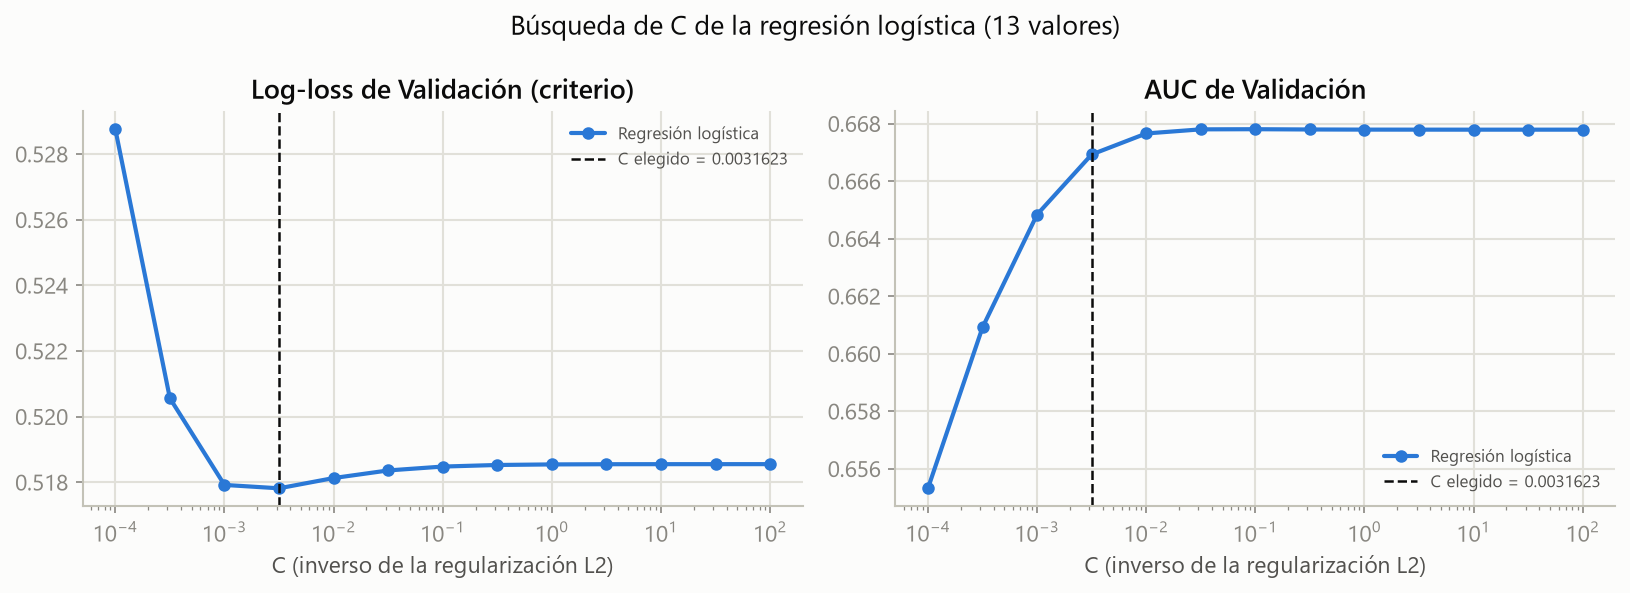

In [11]:
display(Image(filename=str(FIGURAS_BLOG / "pd-busqueda-logistica.png")))  # log-loss y AUC de val contra C

### 3.2 MLP: búsqueda con TPE

Optuna propone configuraciones del espacio de abajo con el muestreador TPE; cada ensayo entrena un MLP y se mide en
val. El presupuesto cuenta todos los ensayos y la suma de los tiempos de entrenamiento (B-pd §3.3).

In [12]:
print("Muestreador:", hpo["muestreador"], "· podador:", hpo["podador"])  # TPE registrado
print(f"Criterio: {hpo['criterio']} · ensayos: {hpo['n_ensayos']} · estados: {hpo['estados']} · "
      f"Σ fit: {hpo['tiempo_total_s']:.1f} s · reloj: {hpo['tiempo_reloj_s']:.1f} s")  # presupuesto
tablas.tabla_espacio(hpo)  # espacio de búsqueda

Muestreador: {'nombre': 'TPESampler', 'semilla': 0, 'n_startup_trials': 10, 'multivariate': True} · podador: NopPruner
Criterio: logloss_val · ensayos: 40 · estados: {'COMPLETE': 40} · Σ fit: 702.4 s · reloj: 706.8 s


,rango o valores,escala
n_capas,"[1, 4]",entero
neuronas,"16, 32, 64, 128, 256",opciones
activacion,"relu, leaky_relu, tanh",opciones
dropout,"[0.0, 0.5]",lineal
l2,"[1e-06, 0.01]",log
optimizador,"adam, sgd",opciones
lr,"[0.0001, 0.01]",log
batch,"256, 512, 1024, 2048",opciones


### 3.3 Trayectoria de la búsqueda

Log-loss de val de cada ensayo completo, el mejor acumulado, el fin de los ensayos aleatorios iniciales y la
logística como referencia.

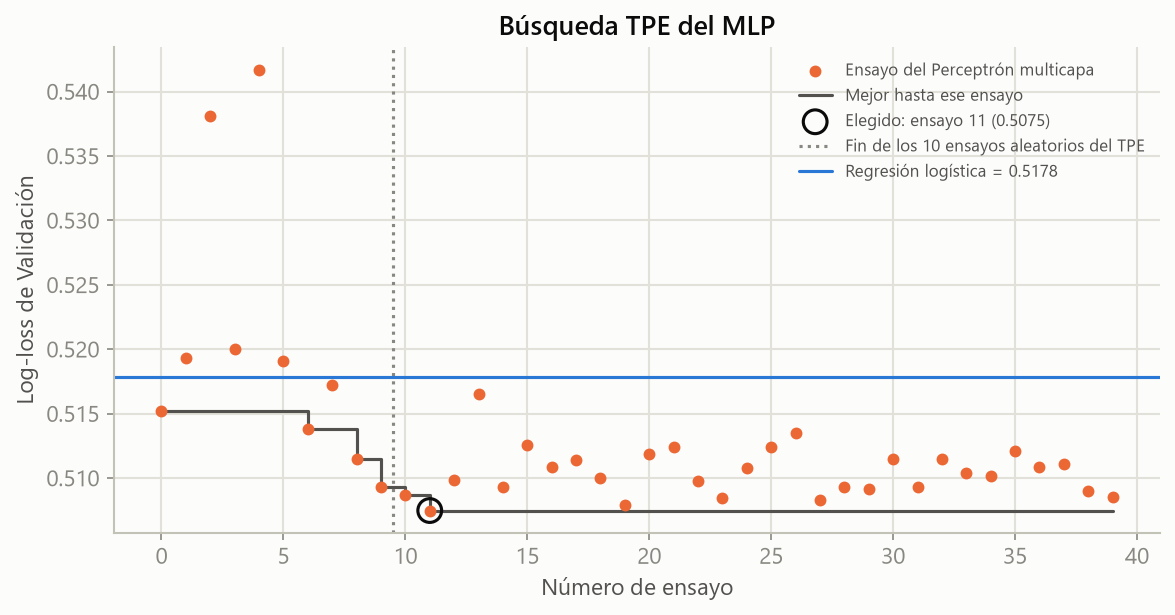

In [13]:
display(Image(filename=str(FIGURAS_BLOG / "pd-busqueda-mlp.png")))  # trayectoria del TPE

### 3.4 Mejores ensayos

Los ensayos completos con menor log-loss de val (empate → menor número de ensayo). `en_borde` indica si lr, l2 o
dropout del mejor quedaron cerca de un extremo de su rango (`null` = no).

In [14]:
print("en_borde del mejor ensayo:", hpo["en_borde"])  # lr, l2, dropout
tablas.tabla_mejores_ensayos(hpo)  # los mejores

en_borde del mejor ensayo: {'lr': None, 'l2': None, 'dropout': None}


,capas,activacion,dropout,l2,optimizador,lr,batch,log-loss val,AUC val,épocas,mejor época,parámetros
ensayo,,,,,,,,,,,,
11,"[32, 16, 32]",relu,0.094166,0.000045,adam,0.004965,512,0.507476,0.670835,13,3,2673
19,"[32, 32, 32]",relu,0.136127,0.000009,adam,0.007255,2048,0.507935,0.669139,20,10,3713
27,"[32, 64, 16, 64]",relu,0.137484,0.000005,adam,0.007363,512,0.508275,0.668852,13,3,5873
23,"[32, 16, 32, 64]",relu,0.126374,0.000056,adam,0.003092,512,0.508463,0.671654,14,4,4817
39,"[32, 64, 128, 256]",relu,0.116493,0.000164,adam,0.001893,512,0.508488,0.670489,13,3,45281


### 3.5 Resumen de las dos búsquedas

Método, configuraciones probadas, criterio, mejor valor del criterio y tiempo (suma de los entrenamientos) de cada
búsqueda, lado a lado.

In [15]:
tablas.tabla_resumen_busquedas(oficial["busqueda"], hpo)  # logística y MLP

,método,configuraciones,criterio,mejor valor,tiempo (s),en el borde
logistica,rejilla de C,13,logloss_val,0.517817,60.750759,no
mlp,TPESampler de Optuna · 10 ensayos aleatorios al inicio · multivariado: sí,40,logloss_val,0.507476,702.416173,lr: no · l2: no · dropout: no


## 4. Modelo final y comparación justa

Misma partición, mismas variables y mismo preprocesador para los dos modelos; el MLP se repite con varias semillas
para separar la diferencia entre modelos de la variación por semilla. Detalle en el
[blog 06](../blog/secciones/06-resultados-pd.md) y las métricas en el [blog 05](../blog/secciones/05-metricas.md).

### 4.1 Arquitectura ganadora

La config del mejor ensayo, que `pd-hpo` escribió en `configs/pd/mlp_final.yaml` y `summary.json` copia, con sus
parámetros entrenables frente a los de la logística.

In [16]:
print(tablas.describir_mlp(resumen["mlp"]))  # arquitectura y procedencia
tablas.tabla_arquitectura(resumen)  # config y parámetros

MLP: capas [32, 16, 32] · activación relu · 2673 parámetros · semilla mediana 20 de 30 · config de la búsqueda: sí


,MLP,logística
capas,"[32, 16, 32]",
activacion,relu,
dropout,0.094166,
l2,0.000045,
optimizador,adam,
lr,0.004965,
momento,0.9,
batch,512,
max_epocas,100,
paciencia,10,


### 4.2 Variación entre semillas

Media, desviación, mejor y peor del MLP en todas sus semillas, con el valor de la logística al lado. El MLP que se
guarda es el de la semilla mediana, elegida con validación (regla impresa abajo).

In [17]:
print(f"Semilla mediana: {resumen['mlp']['semilla_mediana']} · "  # semilla de models/pd_mlp.pt
      f"regla: {resumen['mlp']['criterio_semilla_mediana']}")  # regla de B5
tablas.tabla_semillas(resumen)  # por métrica

Semilla mediana: 20 · regla: orden ascendente por (logloss_val, seed); posición (n - 1) // 2 (n par: mediana inferior; empate: semilla menor)


,MLP media,MLP desv,MLP mejor,MLP peor,semillas,logística
auc_val,0.669586,0.002826,0.673389,0.662314,30,0.666929
gini_val,0.339173,0.005652,0.346779,0.324627,30,0.333857
ks_val,0.243780,0.005041,0.250784,0.231101,30,0.241991
brier_val,0.166847,0.000550,0.165811,0.167938,30,0.169080
logloss_val,0.510108,0.001776,0.506688,0.513770,30,0.517817
auc_test,0.671629,0.003089,0.676647,0.663028,30,0.669647
gini_test,0.343257,0.006177,0.353295,0.326055,30,0.339294
ks_test,0.250043,0.005358,0.258101,0.234018,30,0.246502
brier_test,0.183235,0.001081,0.180818,0.185665,30,0.186522
logloss_test,0.549013,0.003295,0.541667,0.556116,30,0.560005


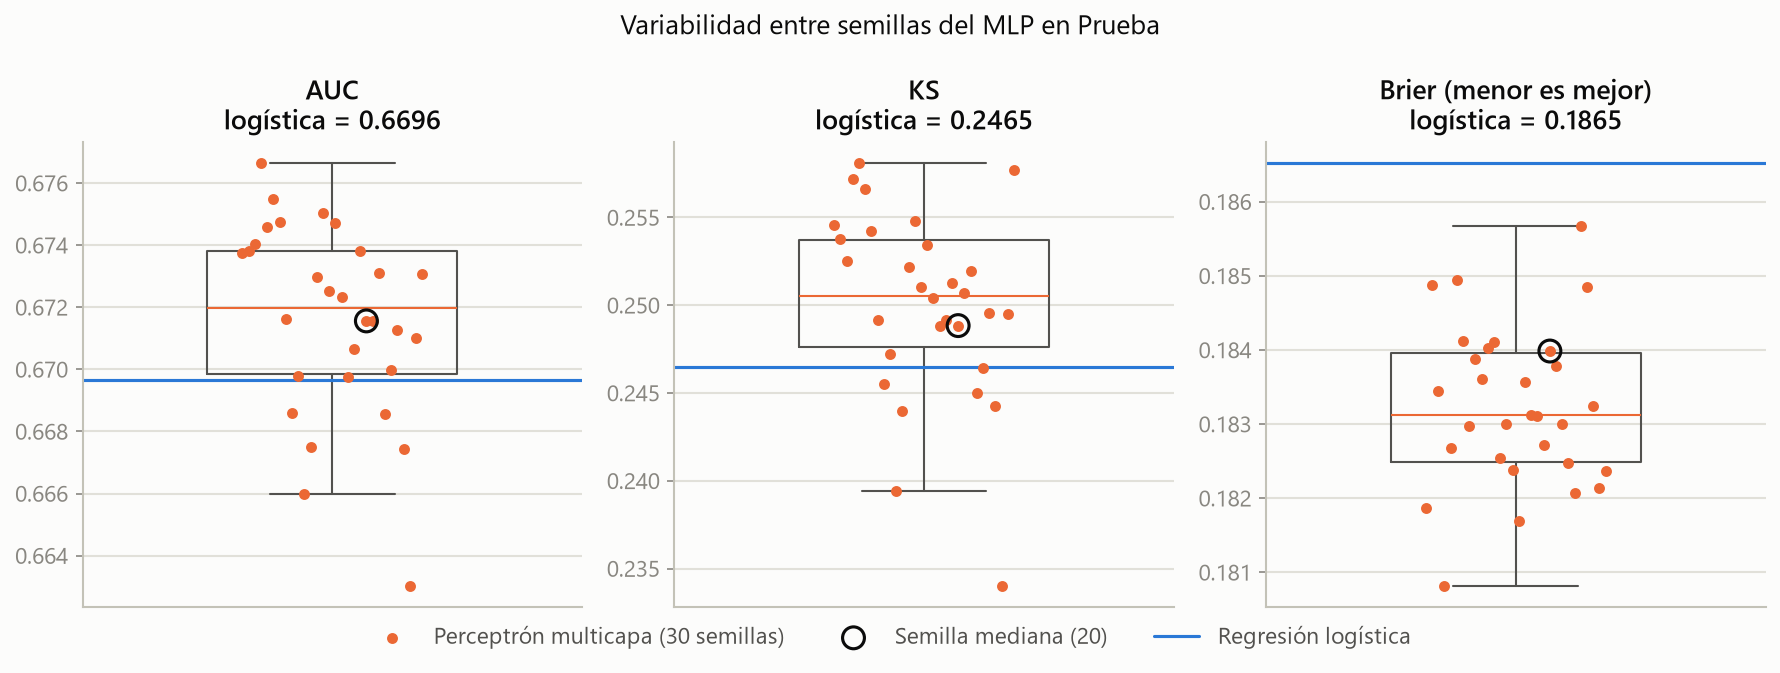

In [18]:
display(Image(filename=str(FIGURAS_BLOG / "pd-semillas.png")))  # AUC, KS y Brier por semilla

### 4.3 MLP − logística

Diferencia de medias con signo y quién es mejor según la métrica (AUC, Gini y KS: mayor; Brier y log-loss: menor), y
en cuántas semillas el MLP supera a la logística (un empate no cuenta).

In [19]:
display(tablas.comparacion(resumen))  # diferencia por métrica
tablas.victorias_por_semilla(oficial["semillas"], resumen)  # victorias por semilla

,logística,MLP (media),MLP − logística,mejor
auc_val,0.666929,0.669586,0.002658,mlp
gini_val,0.333857,0.339173,0.005316,mlp
ks_val,0.241991,0.243780,0.001789,mlp
brier_val,0.169080,0.166847,-0.002233,mlp
logloss_val,0.517817,0.510108,-0.007709,mlp
auc_test,0.669647,0.671629,0.001982,mlp
gini_test,0.339294,0.343257,0.003963,mlp
ks_test,0.246502,0.250043,0.003542,mlp
brier_test,0.186522,0.183235,-0.003287,mlp
logloss_test,0.560005,0.549013,-0.010992,mlp


,victorias del MLP,semillas
auc_val,25,30
gini_val,25,30
ks_val,20,30
brier_val,30,30
logloss_val,30,30
auc_test,24,30
gini_test,24,30
ks_test,23,30
brier_test,30,30
logloss_test,30,30


### 4.4 Discriminación en prueba: ROC y KS

Las curvas de los dos modelos en test (el MLP es la semilla mediana): cuánto separan a los malos de los buenos.

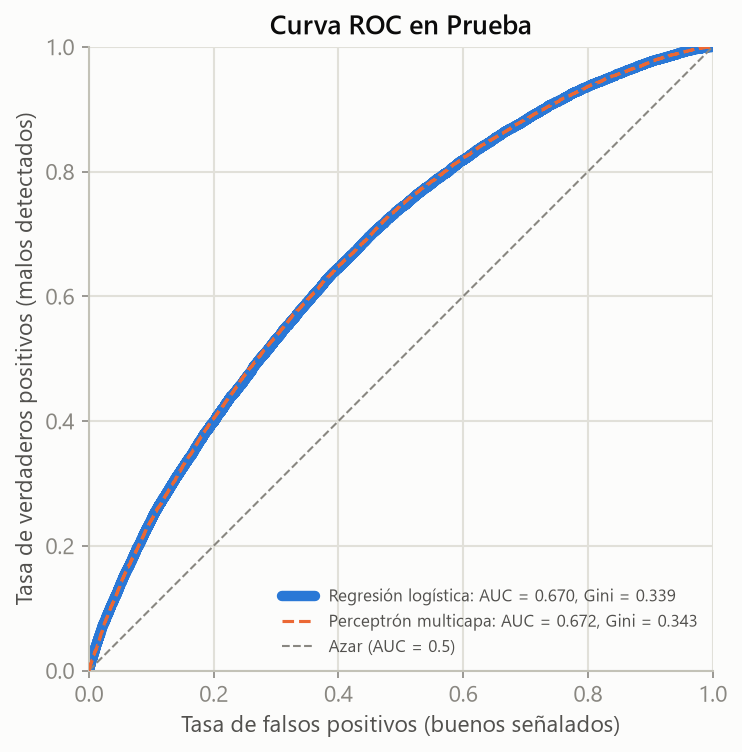

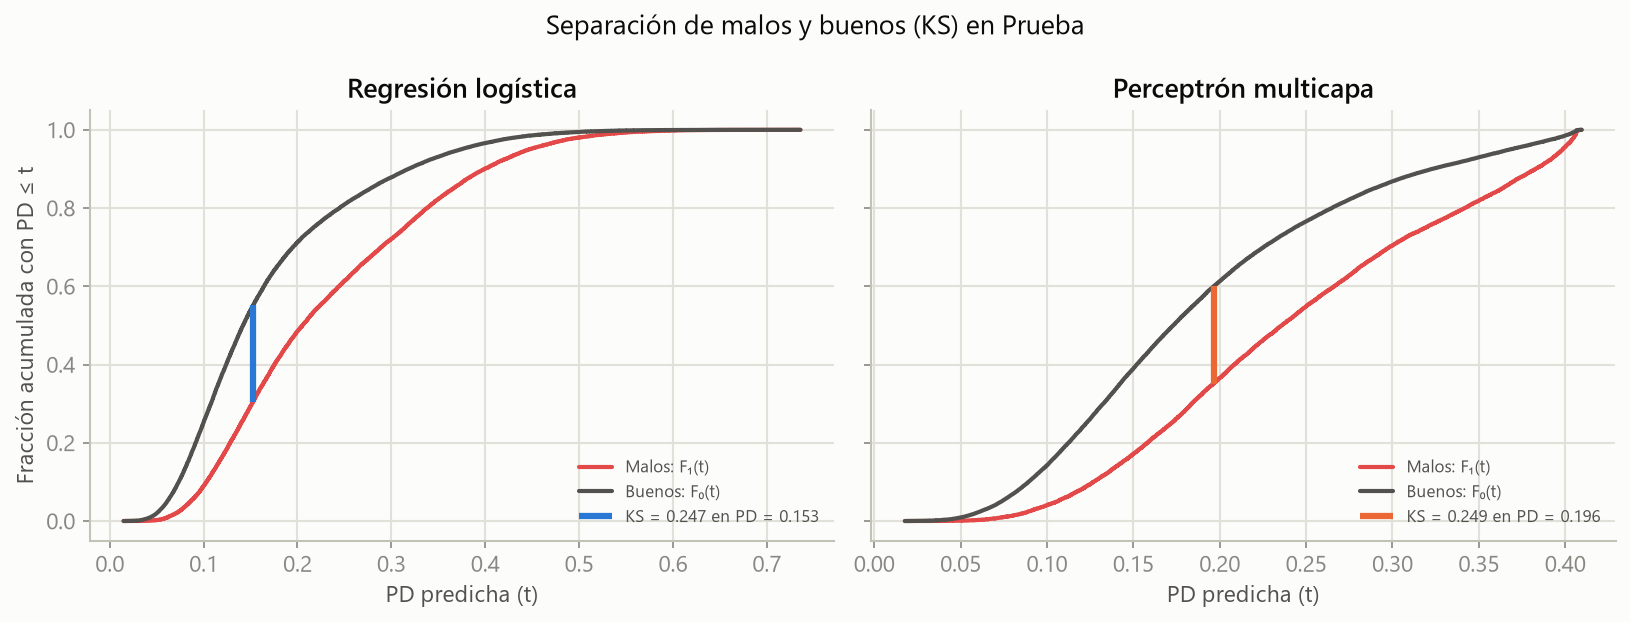

In [20]:
display(Image(filename=str(FIGURAS_BLOG / "pd-roc.png")))  # ROC
display(Image(filename=str(FIGURAS_BLOG / "pd-ks.png")))  # KS

### 4.5 Calibración en prueba

Lectura (B-pd §3.6): los dos modelos ordenan el riesgo pero lo **subestiman**: cuando la tasa observada supera a la
PD media en un bin, el punto queda **por encima** de la diagonal (la tabla cuenta en cuántos bins pasa). En la
sección 2.1 la tasa de malos sube de train a test; eso es consistente con la subestimación, pero aquí no se prueba
que sea su causa. La sección 5 muestra qué implica esta calibración al elegir un corte para aprobar o rechazar.

,PD media,tasa observada,bins con tasa > PD media,bins
logistica,0.186768,0.262171,10,10
mlp,0.204114,0.262171,10,10


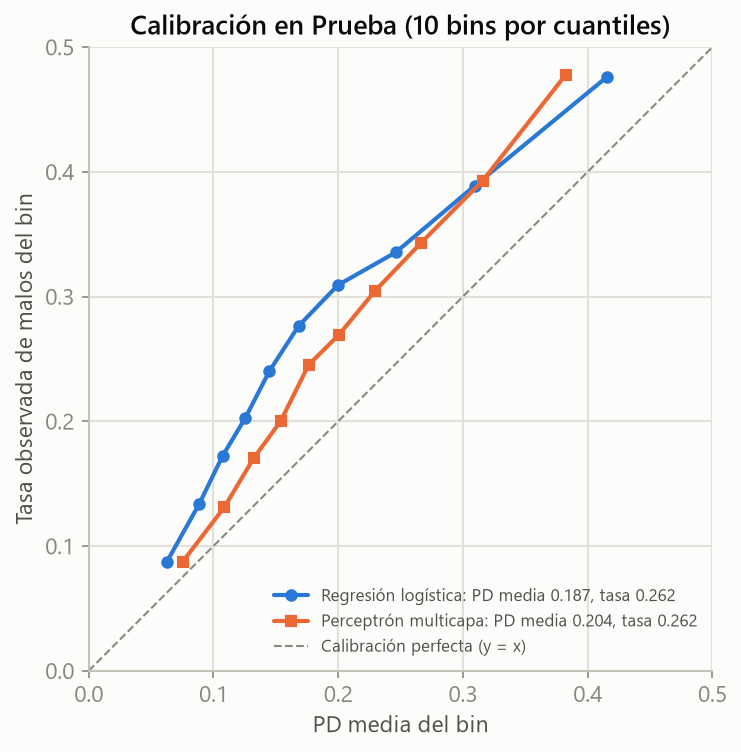

In [21]:
display(tablas.resumen_calibracion(load_json(FIGURAS_BLOG / "pd-calibracion.json")))  # PD media frente a tasa
display(Image(filename=str(FIGURAS_BLOG / "pd-calibracion.png")))  # curva de calibración

### 4.6 Curva de aprendizaje y parada temprana

BCE de train y de val por época de la semilla mediana. El entrenamiento se detiene tras `paciencia` épocas sin
mejorar la pérdida de val y se quedan los pesos de la mejor época (B-pd §3.2).

{'semilla': 20, 'épocas': 11, 'mejor época': 1, 'paciencia': 10, 'máx. épocas': 100, 'mejor pérdida de val': 0.5098706483840942}


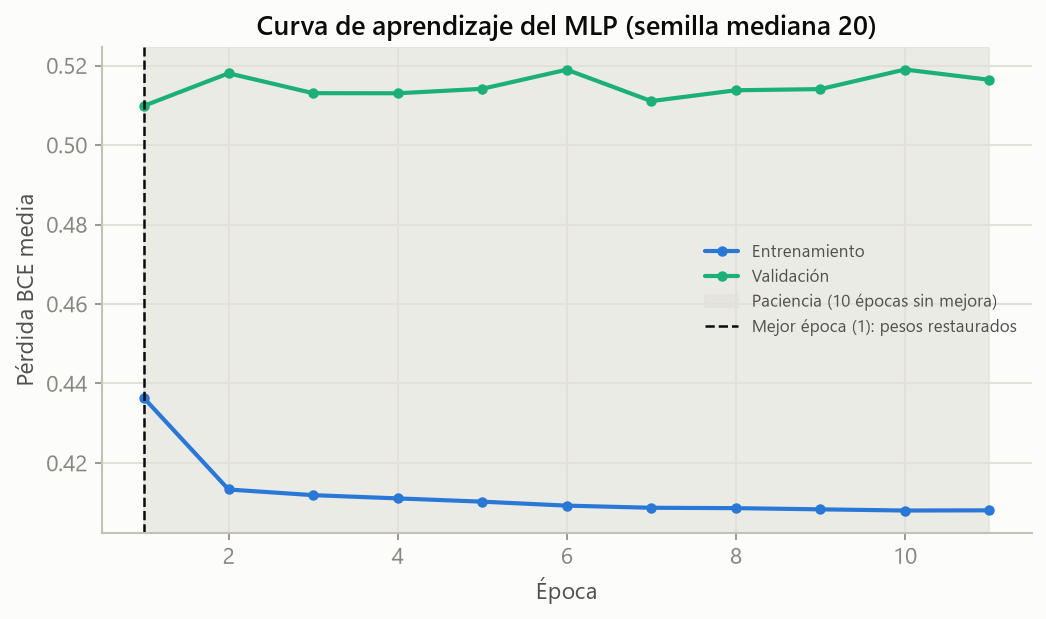

In [22]:
print(tablas.ficha_aprendizaje(oficial["semillas"], resumen))  # épocas, mejor época y paciencia
display(Image(filename=str(FIGURAS_BLOG / "pd-aprendizaje.png")))  # curva de aprendizaje

## 5. De la PD a la decisión: el umbral

La PD se vuelve una decisión al fijar un corte: se rechaza a quien queda por encima. Positivo = malo; FN = malo
aprobado (el error caro), FP = bueno rechazado. La sección **ilustra** cómo cambia la decisión con el corte y con el
costo relativo `L/G`; **no fija una política**, que depende del apetito de riesgo del banco. Solo lee
`umbral.json` (generado con `python scripts/umbral_pd.py --config configs/pd/umbral.yaml`). Definiciones en el
[blog 05](../blog/secciones/05-metricas.md) (§5.8) y resultados en el [blog 06](../blog/secciones/06-resultados-pd.md)
(§6.8).

### 5.1 Frente al modelo trivial

El modelo trivial asigna a todos la misma PD: la tasa de malos de train (y, como piso teórico que usa etiquetas de
prueba, la de test). No ordena (su AUC es la del azar) y su matriz es degenerada: aprueba o rechaza a todos. El
Brier dice cuánto mejoran los modelos sobre esa PD constante.

In [23]:
umbral = load_json(UMBRAL)  # resultados de B11 (solo lectura)
print("Tasa de malos por partición:", umbral["trivial"]["tasas"])  # train, val y test
tablas_umbral.tabla_trivial(umbral)  # Brier del trivial y de los modelos

Tasa de malos por partición: {'train': 0.16302699591574707, 'val': 0.22949968576659288, 'test': 0.26217061790328233}


,PD constante,Brier val,Brier test
Trivial (PD = tasa de train),0.163027,0.181248,0.203267
"Trivial (PD = tasa de prueba, piso)",0.262171,0.177897,0.193437
Regresión logística,,0.169080,0.186522
Perceptrón multicapa,,0.166956,0.183985


### 5.2 Matriz de confusión con el umbral inicial

Con el umbral inicial de la config (impreso abajo), VP, FN, FP y VN en val y test, la sensibilidad (TPR, malos
rechazados entre los malos), la especificidad (TNR, buenos aprobados entre los buenos) y la tasa de rechazo, que
muestra a cuántos rechaza ese corte.

In [24]:
print("Umbral inicial:", umbral["matriz_inicial"]["umbral"])  # de configs/pd/umbral.yaml
tablas_umbral.tabla_matriz_inicial(umbral)  # una fila por (modelo, partición)

Umbral inicial: 0.5


VP     FN   FP     VN       TPR       TNR   rechazo
modelo               split                                                      
Regresión logística  val    288  16510  268  56128  0.017145  0.995248  0.007596
                     test   380  19061  305  54408  0.019546  0.994425  0.009238
Perceptrón multicapa val      0  16798    0  56396  0.000000  1.000000  0.000000
                     test     0  19441    0  54713  0.000000  1.000000  0.000000

### 5.3 Sensibilidad al umbral

TPR, TNR y tasa de rechazo en toda la rejilla de umbrales, en val y test: bajar el corte rechaza a más malos pero
también a más buenos. Ningún umbral es "el correcto" sin decir cuánto cuesta cada error.

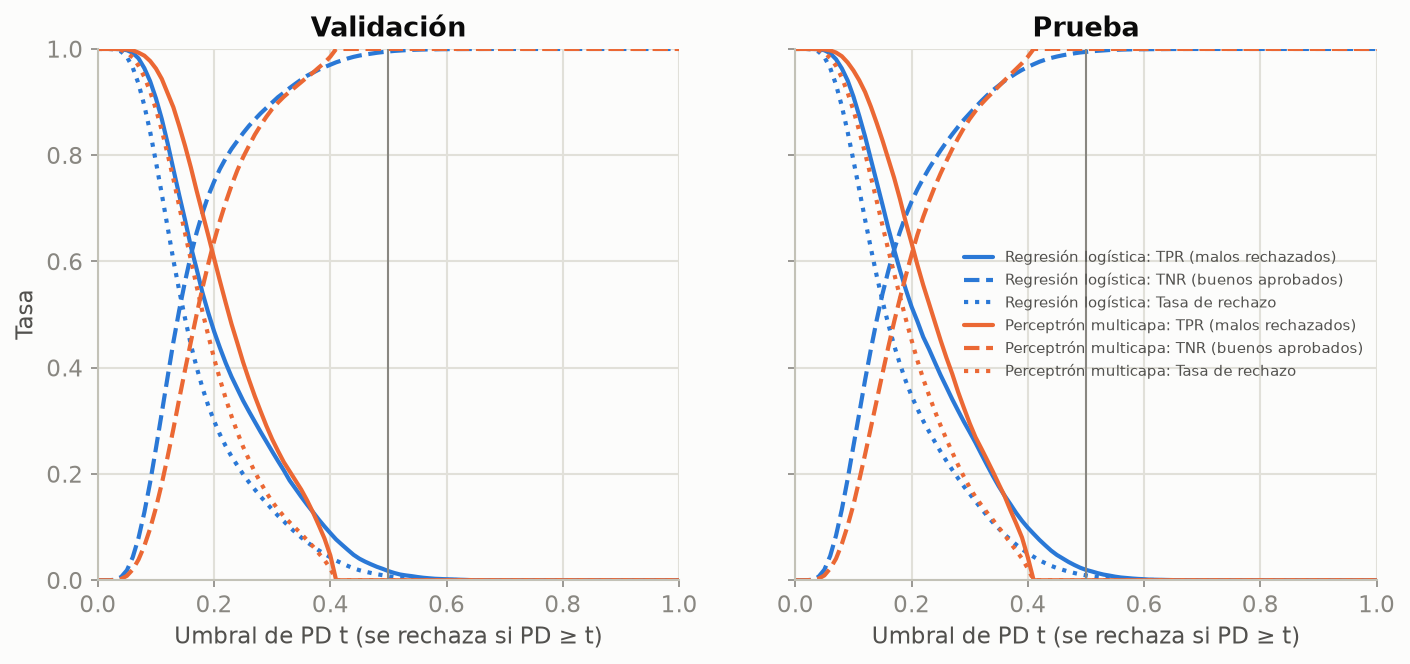

In [25]:
display(Image(filename=str(FIGURAS_BLOG / "pd-umbral-sensibilidad.png")))  # TPR, TNR y rechazo contra el umbral

### 5.4 Cuota por costo y metas de sensibilidad

Para cada razón `L/G` se elige en val la cuota (fracción de créditos de mayor PD que se rechaza) de menor costo
`(L/G)·FN + FP`, y se aplica en test sobre la cohorte: es una política **por lotes o de cuota**, no la decisión
individual en tiempo real de la app. Las metas fijan la menor cuota con TPR de val por encima de la meta. Al final,
la variación entre las semillas del MLP (reentrenadas con la config final) y el control de la semilla mediana.

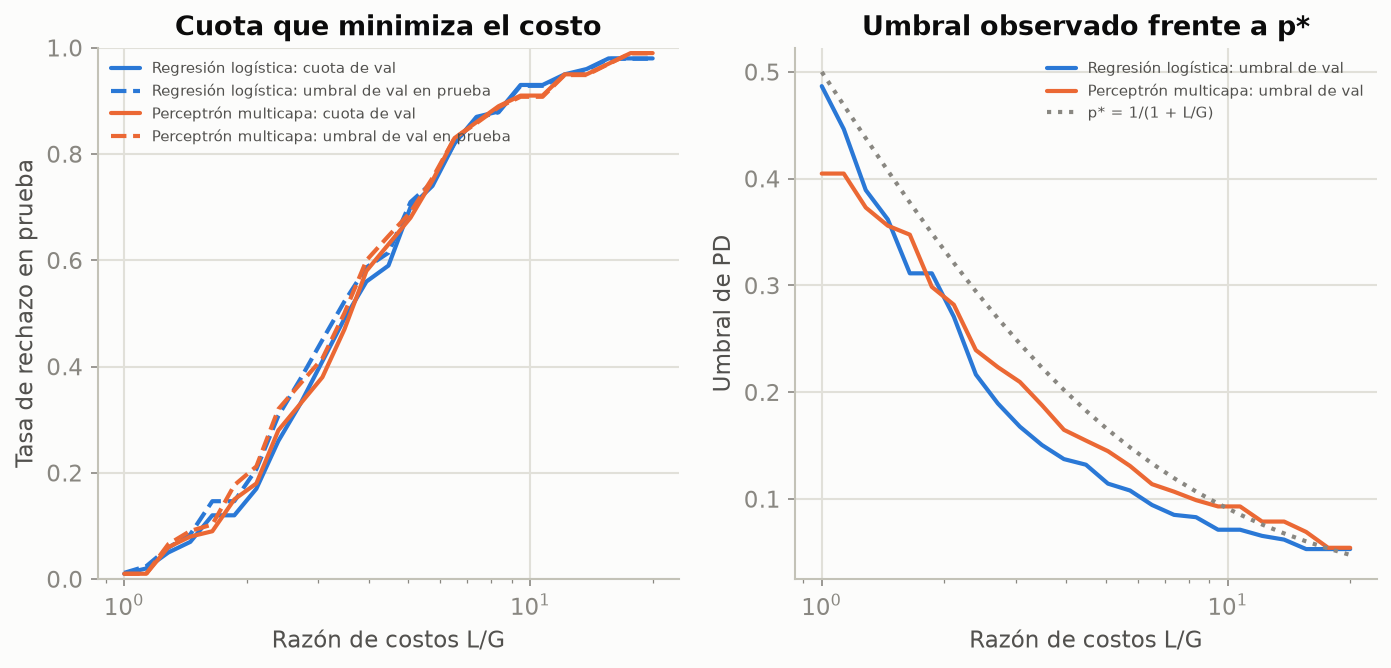

p*  cuota  umbral val  TPR prueba (cuota)  TNR prueba (cuota)  rechazo prueba (cuota)  costo/crédito prueba (cuota)  \
L/G  modelo                                                                                                                                            
2.0  Regresión logística   0.333333   0.16    0.278063            0.275294            0.880961                0.160005                      0.467824   
     Perceptrón multicapa  0.333333   0.17    0.286999            0.288720            0.872169                0.170011                      0.467271   
5.0  Regresión logística   0.166667   0.70    0.114386            0.850059            0.353316                0.700003                      0.673693   
     Perceptrón multicapa  0.166667   0.68    0.144800            0.838074            0.376163                0.680004                      0.672546   
10.0 Regresión logística   0.090909   0.93    0.071218            0.979528            0.087584                0.930011                      0.726879   
     Perceptrón multicapa  0.090909   0.91    0.093034            0.970835            0.111601                0.910012                      0.731950   

                           rechazo prueba (umbral val)  TPR prueba (umbral val)  costo/crédito prueba (umbral val)  
L/G  modelo                                                                                                         
2.0  Regresión logística                      0.195027                 0.323646                           0.464816  
     Perceptrón multicapa                     0.200744                 0.332956                           0.463212  
5.0  Regresión logística                      0.709496                 0.856900                           0.672425  
     Perceptrón multicapa                     0.690576                 0.845121                           0.672034  
10.0 Regresión logística                      0.928352                 0.979116                           0.726407  
     Perceptrón multicapa                     0.907746                 0.969806                           0.732651

cuota  umbral val   TPR val  TPR prueba  TNR prueba  rechazo prueba
meta modelo                                                                                   
0.5  Regresión logística    0.33    0.189443  0.505358    0.495345    0.728748        0.330002
     Perceptrón multicapa   0.33    0.223465  0.507977    0.499563    0.730247        0.330002
0.7  Regresión logística    0.52    0.144693  0.702524    0.701610    0.544514        0.520012
     Perceptrón multicapa   0.52    0.176827  0.704965    0.702124    0.544697        0.520012
0.8  Regresión logística    0.64    0.123923  0.802834    0.804948    0.418603        0.640006
     Perceptrón multicapa   0.64    0.152600  0.807298    0.807829    0.419626        0.640006
0.9  Regresión logística    0.78    0.101332  0.902667    0.904120    0.264087        0.780012
     Perceptrón multicapa   0.78    0.124756  0.904751    0.904274    0.264142        0.780012

Semillas reentrenadas: 30


media      desv     mejor      peor   n
política      métrica                                                      
L/G = 2       TPR prueba         0.283636  0.032388  0.347256  0.229206  30
              TNR prueba         0.875788  0.018647  0.907134  0.838612  30
              aprobación prueba  0.833991  0.022220  0.869987  0.789991  30
L/G = 5       TPR prueba         0.842781  0.012492  0.863433  0.817088  30
              TNR prueba         0.367440  0.020994  0.409354  0.329556  30
              aprobación prueba  0.312327  0.018695  0.349988  0.279998  30
L/G = 10      TPR prueba         0.976421  0.004128  0.983489  0.966000  30
              TNR prueba         0.098231  0.011750  0.123444  0.075320  30
              aprobación prueba  0.078660  0.009731  0.099995  0.059997  30
TPR val ≥ 0.5 TPR prueba         0.498856  0.004515  0.505838  0.486086  30
              TNR prueba         0.730447  0.003706  0.740409  0.716923  30
              aprobación prueba  0.670330  0.003198  0.679990  0.659991  30
TPR val ≥ 0.7 TPR prueba         0.703974  0.003257  0.711743  0.697546  30
              TNR prueba         0.543097  0.004915  0.546817  0.530294  30
              aprobación prueba  0.478322  0.003788  0.479988  0.469995  30
TPR val ≥ 0.8 TPR prueba         0.802887  0.003721  0.809063  0.795638  30
              TNR prueba         0.424642  0.006172  0.432402  0.415642  30
              aprobación prueba  0.364990  0.005082  0.369987  0.359994  30
TPR val ≥ 0.9 TPR prueba         0.900916  0.002774  0.905200  0.895016  30
              TNR prueba         0.268373  0.006005  0.276315  0.262113  30
              aprobación prueba  0.223991  0.004986  0.229994  0.219988  30

{'identica_bit_a_bit': True, 'max_abs_dif': 0.0, 'dentro_tolerancia': True}

In [26]:
display(Image(filename=str(FIGURAS_BLOG / "pd-umbral-costo.png")))  # cuota y costo contra L/G
display(tablas_umbral.tabla_escenarios(umbral))  # escenarios L/G: cuota de val y medidas de prueba
display(tablas_umbral.tabla_metas(umbral))  # metas de sensibilidad
print("Semillas reentrenadas:", umbral["semillas"]["n"])  # n del resumen
display(tablas_umbral.tabla_semillas(umbral))  # media, desv., mejor y peor por política
tablas_umbral.ficha_control(umbral)  # semilla mediana reentrenada = models/pd_mlp.pt

### 5.5 PD absoluta frente a cuota

Si la PD estuviera calibrada, el corte de menor costo esperado sería $p^* = 1/(1 + L/G)$. La tabla lo pone junto al
umbral de val de la cuota elegida (el corte observado) y su brecha, que mide la descalibración; y compara la tasa de
rechazo en test por cuota con la de aplicar ese umbral tal cual: el mismo corte de PD rechaza en test otra fracción
de créditos. Eso es consistente con la deriva de la sección 2.1, pero aquí no se prueba que sea su causa.

In [27]:
print("Tasa de malos por partición:", umbral["trivial"]["tasas"])  # deriva (sección 2.1)
tablas_umbral.tabla_pd_absoluta(umbral)  # p*, corte observado y tasas de rechazo

Tasa de malos por partición: {'train': 0.16302699591574707, 'val': 0.22949968576659288, 'test': 0.26217061790328233}


p*  umbral val  p* − umbral val  rechazo val  rechazo prueba (cuota)  rechazo prueba (umbral val)
L/G  modelo                                                                                                                       
2.0  Regresión logística   0.333333    0.278063         0.055270     0.160013                0.160005                     0.195027
     Perceptrón multicapa  0.333333    0.286999         0.046335     0.170000                0.170011                     0.200744
5.0  Regresión logística   0.166667    0.114386         0.052281     0.700003                0.700003                     0.709496
     Perceptrón multicapa  0.166667    0.144800         0.021867     0.680001                0.680004                     0.690576
10.0 Regresión logística   0.090909    0.071218         0.019691     0.930008                0.930011                     0.928352
     Perceptrón multicapa  0.090909    0.093034        -0.002125     0.910006                0.910012                     0.907746